# Analyse du détecteur ML : données, scores et comparaison des modèles

Ce notebook sert à **comprendre le jeu d'entraînement** (`data/normal.csv`), à **voir les scores** des trois modèles
(Isolation Forest, LOF, statistique) et à **vérifier qu'ils détectent un incident** sans fausse alerte.

Règle de lecture partout : **score < 0 = photo jugée anormale** (une « photo » = 10 s de trafic d'un service).
Une alerte n'est envoyée qu'après 3 photos anormales d'affilée.

Pour l'exécuter : `uv run jupyter lab` depuis le dossier `ML-Detector`, puis ouvrir ce fichier.
Les données viennent de `data/normal.csv` (générées avec le Traffic-Generator, puis `collect`).

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

import config
from app.domaine.detecteur import AnomalyDetector
from app.domaine.evaluation import comparer

plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.3})

CHEMIN_NORMAL = RACINE / "data" / "normal.csv"
SERVICE = "basecamp-shop"            # le service analysé (auth et payment s'ajouteront plus tard)
FEATURE = f"{SERVICE}__req_count"    # la mesure suivie
print("Services surveillés :", list(config.SERVICES))

Services surveillés : ['basecamp-shop']


## 1. Le jeu d'entraînement

In [2]:
df = pd.read_csv(CHEMIN_NORMAL)
df["heure"] = pd.to_datetime(df["timestamp"], unit="s", utc=True)
print(f"{len(df)} photos de 10 s  =  {len(df) * 10 / 60:.0f} minutes de trafic")
print("de", df["heure"].min(), "à", df["heure"].max())
mesures = [c for c in df.columns if "__" in c]
resume = df[mesures].describe().T[["mean", "std", "min", "max"]].round(2)
resume["constante ?"] = resume["std"] == 0
resume

542 photos de 10 s  =  90 minutes de trafic
de 2026-10-21 09:30:10+00:00 à 2026-10-21 11:00:20+00:00


,mean,std,min,max,constante ?
basecamp-shop__req_count,3.24,2.59,1.0,14.0,False
basecamp-shop__denied_count,0.00,0.00,0.0,0.0,True
basecamp-shop__non_success_count,0.00,0.00,0.0,0.0,True
basecamp-shop__error_logs,0.00,0.00,0.0,0.0,True
basecamp-shop__latency_avg_ms,0.00,0.00,0.0,0.0,True


Les colonnes **constantes** (écart-type 0) ne portent aucune information : le détecteur les ignore
(`[info] colonnes ignorées car constantes`). Tant que le trafic normal ne produit ni refus ni erreur, seule
`req_count` est apprise.

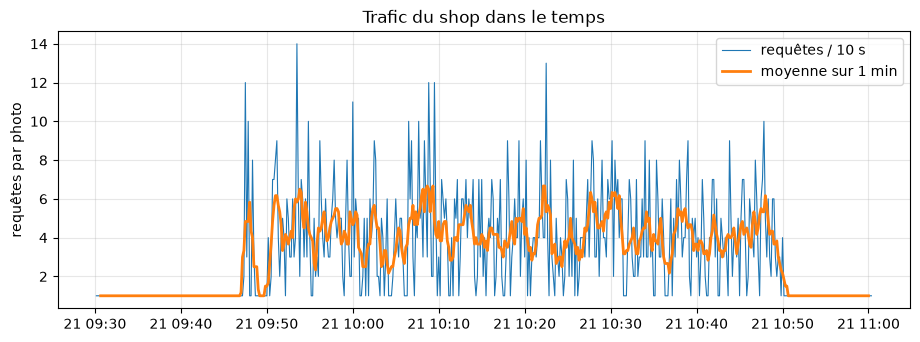

In [3]:
fig, ax = plt.subplots()
ax.plot(df["heure"], df[FEATURE], lw=0.8, label="requêtes / 10 s")
ax.plot(df["heure"], df[FEATURE].rolling(6, center=True).mean(), lw=2, label="moyenne sur 1 min")
ax.set(title="Trafic du shop dans le temps", ylabel="requêtes par photo")
ax.legend()
plt.show()

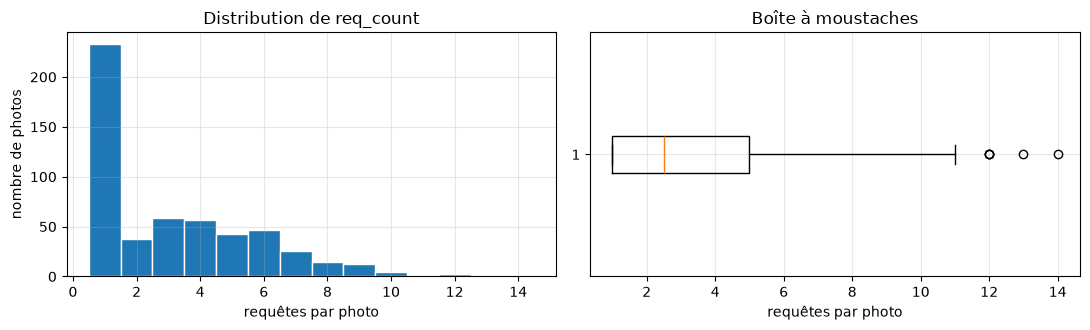

count    542.00
mean       3.24
std        2.59
min        1.00
25%        1.00
50%        2.50
75%        5.00
max       14.00


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
valeurs = df[FEATURE].astype(int)
axes[0].hist(valeurs, bins=np.arange(valeurs.min(), valeurs.max() + 2) - 0.5, edgecolor="white")
axes[0].set(title="Distribution de req_count", xlabel="requêtes par photo", ylabel="nombre de photos")
axes[1].boxplot(valeurs, orientation="horizontal")
axes[1].set(title="Boîte à moustaches", xlabel="requêtes par photo")
plt.tight_layout(); plt.show()
print(valeurs.describe().round(2).to_string())

**À observer** : la forme de la distribution (très étalée vers les grandes valeurs ?) dit au modèle ce qui est
« habituel ». Les valeurs rares mais présentes dans l'entraînement seront jugées normales par le modèle.

## 2. Entraînement des trois modèles

Découpe **dans le temps** : 75 % des photos pour entraîner, 25 % (les plus récentes) pour tester sur du trafic
que le modèle n'a jamais vu. Un modèle par service ; ici un seul service, donc un seul modèle par type.

In [5]:
coupure = int(len(df) * 0.75)
cols = ["timestamp", *mesures]
entrainement = df.loc[:coupure - 1, cols].reset_index(drop=True)
test = df.loc[coupure:, cols].set_index("timestamp")
print(f"entraînement : {len(entrainement)} photos | test : {len(test)} photos")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    detecteurs = {
        nom: AnomalyDetector(nom).fit(entrainement.drop(columns="timestamp"))
        for nom in ("isolation_forest", "lof", "statistique")
    }
list(detecteurs)

entraînement : 406 photos | test : 136 photos
[info] colonnes ignorées car constantes : ['basecamp-shop__denied_count', 'basecamp-shop__non_success_count', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
[info] colonnes ignorées car constantes : ['basecamp-shop__denied_count', 'basecamp-shop__non_success_count', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']
[info] colonnes ignorées car constantes : ['basecamp-shop__denied_count', 'basecamp-shop__non_success_count', 'basecamp-shop__error_logs', 'basecamp-shop__latency_avg_ms']


['isolation_forest', 'lof', 'statistique']

## 3. Un incident de test

Pour savoir si les modèles détectent quelque chose, on **injecte un pic** dans le trafic de test (comme un flood).
Les paramètres sont modifiables : un facteur plus petit rend l'incident plus discret et plus difficile à détecter.

In [6]:
DEBUT_PHOTO = 50      # numéro de la photo où le pic commence (dans le jeu de test)
DUREE_PHOTOS = 30     # 30 photos = 5 minutes
FACTEUR = 8           # trafic multiplié par 8
SUPPLEMENT = 20       # requêtes en plus par photo

def injecter_pic(base, debut, duree, facteur, supplement):
    inc = base.copy()
    fenetre = inc.index[debut:debut + duree]
    inc.loc[fenetre, FEATURE] = (inc.loc[fenetre, FEATURE] * facteur + supplement).round()
    inc["_verite"] = ""
    inc.loc[fenetre, "_verite"] = SERVICE
    return inc

test_incident = injecter_pic(test, DEBUT_PHOTO, DUREE_PHOTOS, FACTEUR, SUPPLEMENT)
fenetre_incident = (test_incident.index[DEBUT_PHOTO], test_incident.index[DEBUT_PHOTO + DUREE_PHOTOS - 1])
test_incident[[FEATURE, "_verite"]].iloc[DEBUT_PHOTO - 2:DEBUT_PHOTO + 3]

,basecamp-shop__req_count,_verite
timestamp,,
1792579550,1.0,
1792579560,2.0,
1792579570,68.0,basecamp-shop
1792579580,60.0,basecamp-shop
1792579590,52.0,basecamp-shop


## 4. Les scores au fil du temps

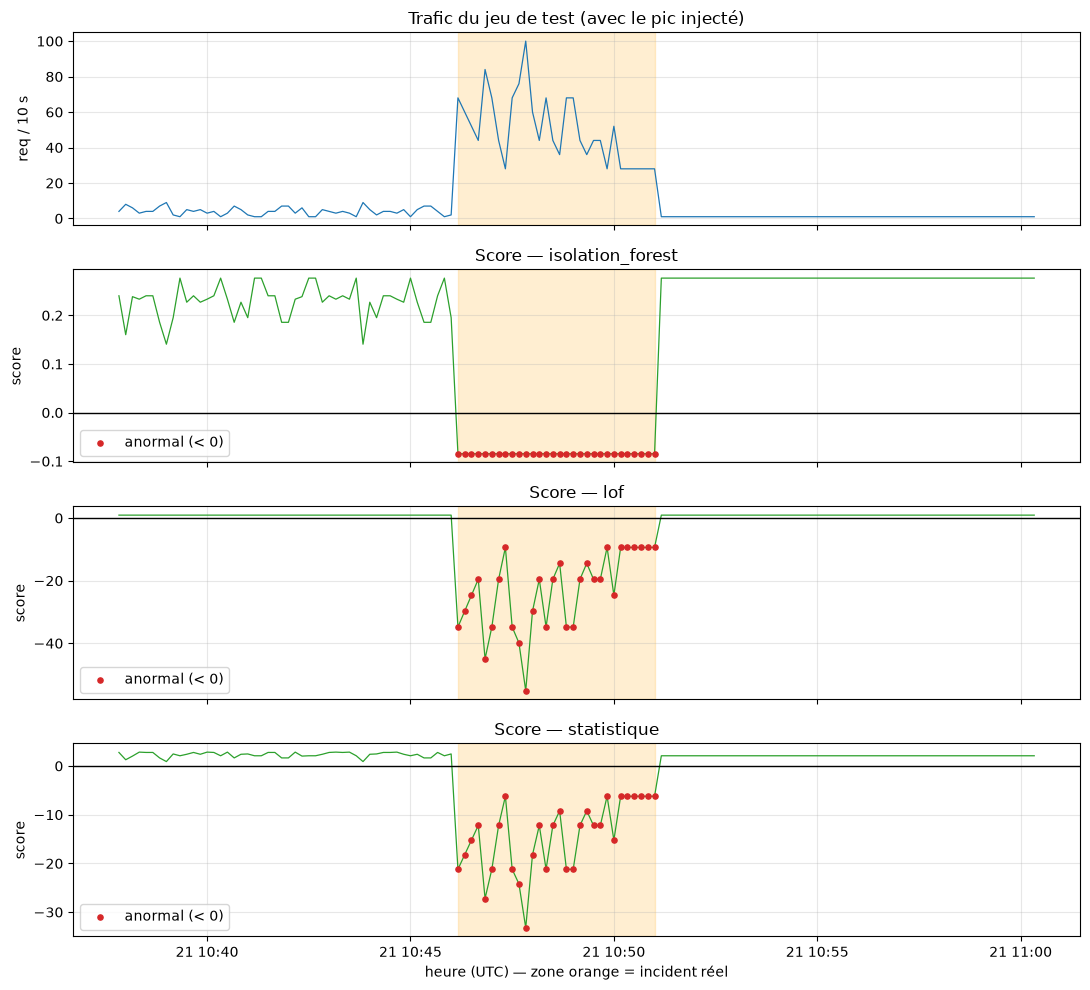

In [7]:
COLONNE_SCORE = f"score_{SERVICE}"
scores = {nom: det.score(test_incident.drop(columns="_verite")) for nom, det in detecteurs.items()}
temps = pd.to_datetime(test_incident.index, unit="s", utc=True)
t0, t1 = (pd.to_datetime(x, unit="s", utc=True) for x in fenetre_incident)

fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
axes[0].plot(temps, test_incident[FEATURE], lw=0.9, color="tab:blue")
axes[0].set(title="Trafic du jeu de test (avec le pic injecté)", ylabel="req / 10 s")
for ax, (nom, s) in zip(axes[1:], scores.items()):
    ax.plot(temps, s[COLONNE_SCORE], lw=0.9, color="tab:green")
    ax.axhline(0, color="black", lw=1)
    anormal = (s[COLONNE_SCORE] < 0).to_numpy()
    ax.scatter(temps[anormal], s[COLONNE_SCORE].to_numpy()[anormal], color="tab:red", s=14, zorder=3, label="anormal (< 0)")
    ax.set(title=f"Score — {nom}", ylabel="score")
    ax.legend(loc="lower left")
for ax in axes:
    ax.axvspan(t0, t1, color="orange", alpha=0.18)
axes[-1].set_xlabel("heure (UTC) — zone orange = incident réel")
plt.tight_layout(); plt.show()

**Comment lire** : la zone orange est l'incident réel. Un bon modèle a ses points rouges (score < 0) **dans** la
zone orange, et aucun en dehors. Les points rouges isolés hors de la zone sont des *fausses alertes potentielles*
(elles ne déclenchent une alerte que si 3 sont consécutives).

## 5. Où chaque modèle place-t-il son seuil ?

Avec une seule mesure, un modèle revient à dire « au-dessus (ou en dessous) de telle valeur de `req_count`, c'est
anormal ». Cette courbe montre le score de chaque modèle pour toutes les valeurs possibles : là où elle passe sous 0,
le modèle crie à l'anomalie. Les échelles diffèrent d'un modèle à l'autre : **comparer les croisements avec 0**,
pas les hauteurs.

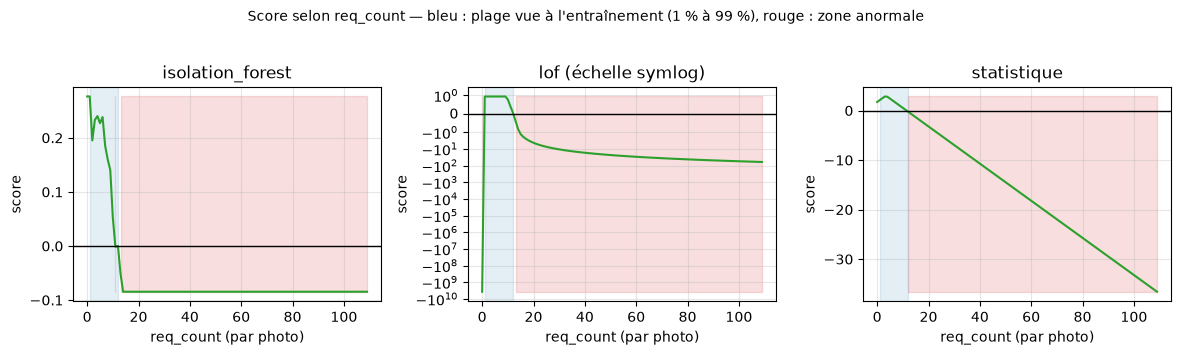

In [8]:
grille = pd.DataFrame({FEATURE: np.arange(0, int(test_incident[FEATURE].max()) + 10)})
bas_normal, haut_normal = entrainement[FEATURE].quantile([0.01, 0.99])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (nom, det) in zip(axes, detecteurs.items()):
    courbe = det.modeles[SERVICE].decision_function(grille)
    ax.plot(grille[FEATURE], courbe, color="tab:green")
    ax.axhline(0, color="black", lw=1)
    ax.fill_between(grille[FEATURE], courbe.min(), courbe.max(), where=courbe < 0, color="tab:red", alpha=0.15)
    ax.axvspan(bas_normal, haut_normal, color="tab:blue", alpha=0.12)
    ax.set(title=nom, xlabel="req_count (par photo)", ylabel="score")
    if courbe.max() - courbe.min() > 1000:    # LOF : valeur jamais vue = score gigantesque, échelle écrasée
        ax.set_yscale("symlog", linthresh=1)
        ax.set_title(f"{nom} (échelle symlog)")
plt.suptitle("Score selon req_count — bleu : plage vue à l'entraînement (1 % à 99 %), rouge : zone anormale",
             y=1.03, fontsize=10)
plt.tight_layout(); plt.show()

**Ce que montrent ces courbes** (avec les données actuelles) :

- **Isolation Forest** : le score tombe sous 0 juste au-dessus de la plage normale puis **se stabilise** (« plateau »).
  Il dit *anormal*, mais ne distingue pas un pic modéré d'un pic énorme : l'intensité vient d'ailleurs (l'écart en
  écarts-types calculé par `expliquer`, qui sert à la gravité).
- **LOF** et **statistique** : le score continue de descendre quand l'écart grandit, donc ils mesurent l'ampleur.
- **LOF** : une valeur jamais vue à l'entraînement (ici 0 requête, le minimum appris est 1) donne un score
  gigantesque. Ces valeurs très négatives sont probablement dues aux nombreux points identiques (beaucoup de photos
  à 1 ou 2 requêtes), ce qui rend la densité locale presque infinie : à surveiller quand on aura plusieurs mesures.
- La fin du jeu de test est plate (1 requête par photo) : c'est le bruit de fond du front après l'arrêt du générateur.

## 6. Bilan : fausses alertes et détection

In [9]:
# Taux de photos jugées anormales sur du trafic NORMAL jamais vu (doit rester proche de 0 %)
normal_scores = {nom: det.score(test.copy()) for nom, det in detecteurs.items()}
fausses = pd.Series(
    {nom: (s[COLONNE_SCORE] < 0).mean() * 100 for nom, s in normal_scores.items()},
    name="% de photos normales jugées anormales",
)
display(fausses.round(1).to_frame())

# Détection sur l'incident injecté (même logique que le service : 3 photos anormales d'affilée)
bilan = comparer(test_incident, detecteurs, n_consecutifs=config.N_CONSECUTIFS)
bilan[[c for c in ["modele", "type", "delai_s", "gravite", "bon_service", "nb_fausses_alertes"] if c in bilan.columns]]

,% de photos normales jugées anormales
isolation_forest,0.0
lof,0.0
statistique,0.0


,modele,type,delai_s,gravite,bon_service,nb_fausses_alertes
0,isolation_forest,detecte,20,critique,True,0
1,lof,detecte,20,critique,True,0
2,statistique,detecte,20,critique,True,0


**Conclusion à tirer** (à adapter selon vos résultats) :

- `delai_s` : secondes entre le début réel de l'incident et l'alerte (minimum 20 s à cause de la règle des 3 photos).
- `nb_fausses_alertes` : alertes déclenchées *avant* l'incident, doit rester à 0.
- Avec une seule mesure, les trois modèles sont proches : les différences apparaîtront quand `auth`, `payment` et des
  refus (`denied_count`) donneront plusieurs mesures par service.

**Limites** : l'incident est injecté dans du trafic réel, pas une vraie attaque ; le trafic normal n'a pas de cycle
jour/nuit ; un seul jeu de test de ~25 minutes.